# Choose and compare models

**Run this notebook:** in Colab, choose **Runtime → Run all**. The first cell prepares METIS automatically using uv; a fresh runtime needs this setup again. These short tutorials use a CPU. Locally, select your [METIS Python environment](https://ojwatson.github.io/metis/basics/installing_metis.html).

The outputs below were generated when the documentation was built. [Source revision `ebd964ed89e4`](https://github.com/OJWatson/metis/tree/ebd964ed89e468e4f03197f2c0217c581e294b97).

In [ ]:
#@title Prepare METIS (run once per runtime)
"""Embedded in notebook downloads: prepare their disposable Colab runtime with uv."""

import importlib
import importlib.metadata
import importlib.util
import io
import json
import os
from pathlib import Path
import platform
import re
import shutil
import subprocess
import sys
import tarfile
import urllib.request


UV_VERSION = "0.7.22"
INSTALL_GUIDE = "https://ojwatson.github.io/metis/basics/installing_metis.html"


def _installed_version(package):
    try:
        return importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        return None


def _compatible_pin(package, minimum, maximum=None):
    """Preserve compatible binary libraries already supplied by Colab."""
    version = _installed_version(package)
    if version is None:
        return None
    match = re.match(r"^(\d+)\.(\d+)(?:\.(\d+))?", version)
    if match is None:
        return None
    release = tuple(int(value or 0) for value in match.groups())
    if release < minimum or (maximum is not None and release >= maximum):
        return None
    return f"{package}=={version}"


def _uv_executable(directory):
    installed = shutil.which("uv")
    if installed:
        return installed
    destination = directory / "uv"
    if not destination.exists():
        architecture = {"x86_64": "x86_64", "aarch64": "aarch64"}.get(platform.machine())
        if architecture is None:
            raise RuntimeError(f"Unsupported Colab CPU architecture: {platform.machine()}")
        archive_name = f"uv-{architecture}-unknown-linux-gnu"
        url = (
            f"https://github.com/astral-sh/uv/releases/download/{UV_VERSION}/"
            f"{archive_name}.tar.gz"
        )
        with urllib.request.urlopen(url, timeout=120) as response:
            archive_bytes = response.read()
        with tarfile.open(fileobj=io.BytesIO(archive_bytes), mode="r:gz") as archive:
            # Read one known member, without extracting arbitrary archive paths.
            binary = archive.extractfile(f"{archive_name}/uv")
            if binary is None:
                raise RuntimeError("The uv release archive contains no executable")
            destination.write_bytes(binary.read())
        destination.chmod(0o755)
    return str(destination)


def _project_text(revision):
    dependencies = [
        f"metis-surrogate[plots,pandas] @ git+https://github.com/OJWatson/metis.git@{revision}",
        "torch==2.10.0",
    ]
    for package, minimum, maximum in [
        ("numpy", (2, 0, 0), (3, 0, 0)),
        ("matplotlib", (3, 9, 0), (4, 0, 0)),
        ("pandas", (2, 2, 0), (4, 0, 0)),
        ("pyarrow", (18, 0, 0), None),
        ("polars", (1, 37, 0), (3, 0, 0)),
    ]:
        pin = _compatible_pin(package, minimum, maximum)
        if pin:
            dependencies.append(pin)
    return (
        '[project]\nname = "metis-colab-tutorial"\nversion = "0.0.0"\n'
        f'requires-python = ">={sys.version_info.major}.{sys.version_info.minor},'
        f'<{sys.version_info.major}.{sys.version_info.minor + 1}"\n'
        f"dependencies = {json.dumps(dependencies)}\n\n"
        '[tool.uv]\npackage = false\n\n'
        '[tool.uv.sources]\ntorch = { index = "pytorch-cpu" }\n\n'
        '[[tool.uv.index]]\nname = "pytorch-cpu"\n'
        'url = "https://download.pytorch.org/whl/cpu"\nexplicit = true\n'
    )


def _metis_origin():
    try:
        return importlib.metadata.distribution("metis-surrogate").read_text("direct_url.json")
    except importlib.metadata.PackageNotFoundError:
        return None


def prepare_colab(revision):
    """Install only inside Colab; local notebooks use the selected METIS environment."""
    if not re.fullmatch(r"[a-f0-9]{40}", revision):
        raise ValueError("Notebook setup needs an exact 40-character source revision")
    try:
        in_colab = (
            importlib.util.find_spec("google.colab") is not None
            and bool(os.environ.get("COLAB_RELEASE_TAG") or os.environ.get("COLAB_BACKEND_VERSION"))
        )
    except ModuleNotFoundError:
        in_colab = False
    if not in_colab:
        if _installed_version("metis-surrogate") is None:
            raise RuntimeError(f"Select a Python environment containing METIS: {INSTALL_GUIDE}")
        print(f"Using local METIS {_installed_version('metis-surrogate')}.")
        return
    if sys.version_info < (3, 11):
        raise RuntimeError("This tutorial requires a Colab runtime with Python 3.11 or newer.")

    directory = Path("/content/.metis-notebooks")
    directory.mkdir(parents=True, exist_ok=True)
    (directory / "pyproject.toml").write_text(_project_text(revision), encoding="utf-8")
    loaded = {
        package: str(getattr(sys.modules[package], "__version__", _installed_version(package)))
        for package in ("numpy", "pandas", "torch", "matplotlib", "pyarrow", "polars")
        if package in sys.modules
    }
    metis_was_loaded = "metis" in sys.modules
    previous_metis_origin = _metis_origin()
    if metis_was_loaded:
        # Retain the import's identity if the user reruns setup after a restart
        # warning without actually restarting the Python process.
        previous_metis_origin = sys.modules["metis"].__dict__.setdefault(
            "_notebook_runtime_origin", previous_metis_origin,
        )
    environment = os.environ.copy()
    # Colab is a disposable runtime. Keep its unrelated packages and its active
    # notebook interpreter, instead of adding a second environment to sys.path.
    environment["UV_PROJECT_ENVIRONMENT"] = sys.prefix
    environment.pop("VIRTUAL_ENV", None)
    print("Preparing this Colab runtime with uv (CPU tutorial environment)…")
    result = subprocess.run(
        [_uv_executable(directory), "sync", "--inexact", "--no-dev", "--no-editable",
         "--project", str(directory), "--python", sys.executable],
        env=environment, text=True, capture_output=True,
    )
    if result.returncode:
        raise RuntimeError(f"METIS setup failed:\n{result.stdout}\n{result.stderr}")
    importlib.invalidate_caches()
    changed = [package for package, before in loaded.items() if _installed_version(package) != before]
    if metis_was_loaded and _metis_origin() != previous_metis_origin:
        changed.append("metis")
    if changed:
        raise RuntimeError(
            "Setup updated already-loaded libraries (" + ", ".join(changed) + "). "
            "Choose Runtime > Restart session, then Run all. Setup will reuse its installed packages."
        )
    print(f"METIS {_installed_version('metis-surrogate')} is ready. Continue with the tutorial.")


prepare_colab("ebd964ed89e468e4f03197f2c0217c581e294b97")


Start with what you need the surrogate to return, then compare candidates on the
same validation simulations. For local setup, see
[installation](https://ojwatson.github.io/metis/basics/installing_metis.html).

| You need… | Start with… | Check… |
|---|---|---|
| A typical trajectory for a dashboard | `mlp` | Errors in the outputs users inspect |
| A trajectory generated one timepoint at a time | `transformer` | Full generated paths, not only training loss |
| Random simulator-like realizations | `flow_matching` or `itarflow` | Mean error, CRPS, predictive intervals and realistic paths |
| A learned continuous density for parameter fitting | `itarflow` | Density and generative checks; see [likelihood inference](https://ojwatson.github.io/metis/sbi/vi-mcmc.html) |

## Compare two models with a simple baseline

Here an MLP and transformer each receive 500 training steps on the bundled SIRDS
bank. A baseline predicts the training bank's average trajectory for every input.
This is a small worked comparison, not a general ranking of the architectures.

In [1]:
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from metis import load_example, Surrogate, TrainingConfig

torch.set_num_threads(2)
split = load_example().split(seed=42)
models = {}
rows = []
for family in ("mlp", "transformer"):
    model = Surrogate(family).fit(
        split.train, split.validation,
        config=TrainingConfig(steps=500, eval_every=50, seed=42),
    )
    # Validation already chose checkpoint weights; use it for model selection too.
    # The warning is expected here. It would matter if this were called a test.
    with warnings.catch_warnings():
        warnings.filterwarnings("ignore", message="This bank overlaps training or tuning groups;.*", category=UserWarning)
        report = model.evaluate(split.validation)
    models[family] = model
    rows.append({"model": family, **report.metrics})

baseline = split.train.outputs.mean(axis=0)
error = baseline[None] - split.validation.outputs
rows.append({"model": "training mean", "rmse": np.sqrt(np.mean(error**2)),
             "mae": np.mean(np.abs(error))})
comparison = pd.DataFrame(rows).set_index("model")
comparison.round(2)

/home/runner/work/metis/metis/src/metis/surrogate.py:672: UserWarning: Inputs outside the training ranges for ['gamma']; predictions extrapolate and are not clipped.
  array = self._inputs(inputs)
/home/runner/work/metis/metis/src/metis/surrogate.py:672: UserWarning: Inputs outside the training ranges for ['I_0']; predictions extrapolate and are not clipped.
  array = self._inputs(inputs)


/home/runner/work/metis/metis/src/metis/surrogate.py:672: UserWarning: Inputs outside the training ranges for ['gamma']; predictions extrapolate and are not clipped.
  array = self._inputs(inputs)
/home/runner/work/metis/metis/src/metis/surrogate.py:672: UserWarning: Inputs outside the training ranges for ['I_0']; predictions extrapolate and are not clipped.
  array = self._inputs(inputs)


,rmse,mae,replicate_mean_rmse
model,,,
mlp,43.26,28.25,38.91
transformer,107.09,70.21,105.41
training mean,170.24,120.81,NaN


All four SIRDS outputs are counts. Here the decision rule is the lowest
validation RMSE pooled across those outputs. Use a different, explicit rule
when some outputs matter more or their units differ.

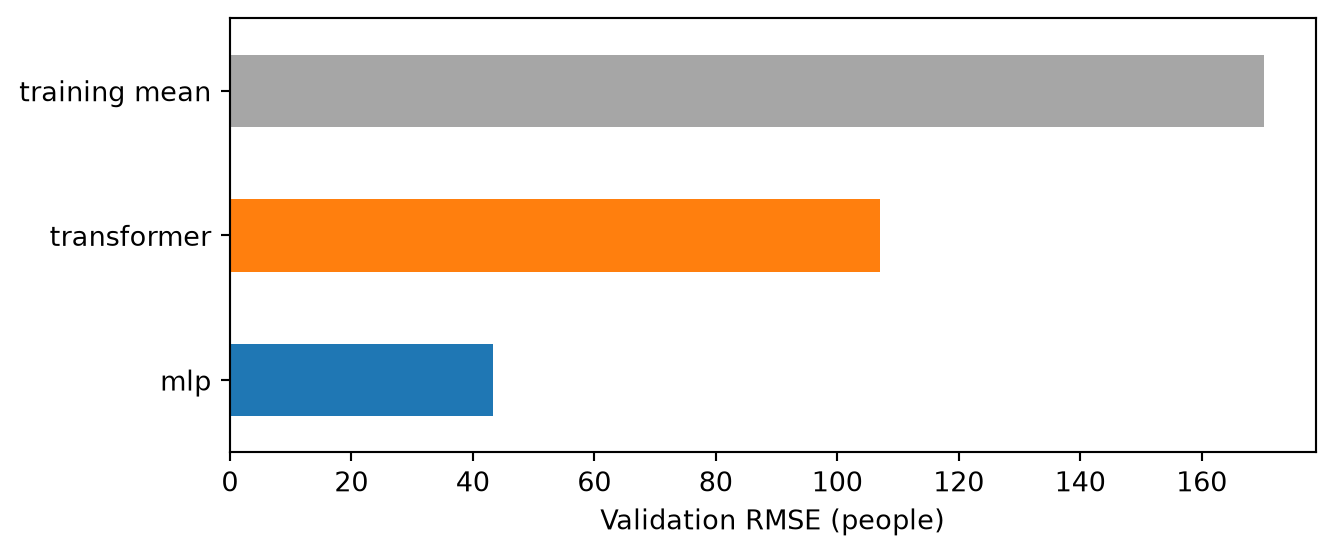

In [2]:
#| code-fold: true
#| code-summary: Show plotting code
#| label: fig-model-comparison
#| fig-cap: 'MLP and transformer fitted to the same SIRDS training partition for 500 steps: autonomous prediction RMSE on the validation partition, compared with the training-mean baseline.'
fig, ax = plt.subplots(figsize=(7, 3))
comparison["rmse"].plot.barh(ax=ax, color=["C0", "C1", "0.65"])
ax.set(xlabel="Validation RMSE (people)", ylabel="")
fig.tight_layout()
plt.show()

*MLP and transformer fitted to the same SIRDS training partition for 500 steps: autonomous prediction RMSE on the validation partition, compared with the training-mean baseline.*

## Test the selected model

Select using validation, then evaluate that choice on test settings held aside
until now. If a baseline wins, it is a reason to improve the candidate models
before deploying them.

In [3]:
selected = comparison.loc[list(models), "rmse"].idxmin()
print("Selected neural model:", selected)
print("Best model including baseline:", comparison["rmse"].idxmin())
final_report = models[selected].evaluate(split.test)
final_report.by_output.to_pandas().round(2)

Selected neural model: mlp
Best model including baseline: mlp


/home/runner/work/metis/metis/src/metis/surrogate.py:672: UserWarning: Inputs outside the training ranges for ['I_0', 'gamma', 'omega', 'mu']; predictions extrapolate and are not clipped.
  array = self._inputs(inputs)


,output,rmse,mae
0,S_t,55.25,40.39
1,I_t,32.08,23.47
2,R_t,42.00,30.40
3,D_t,14.21,10.33


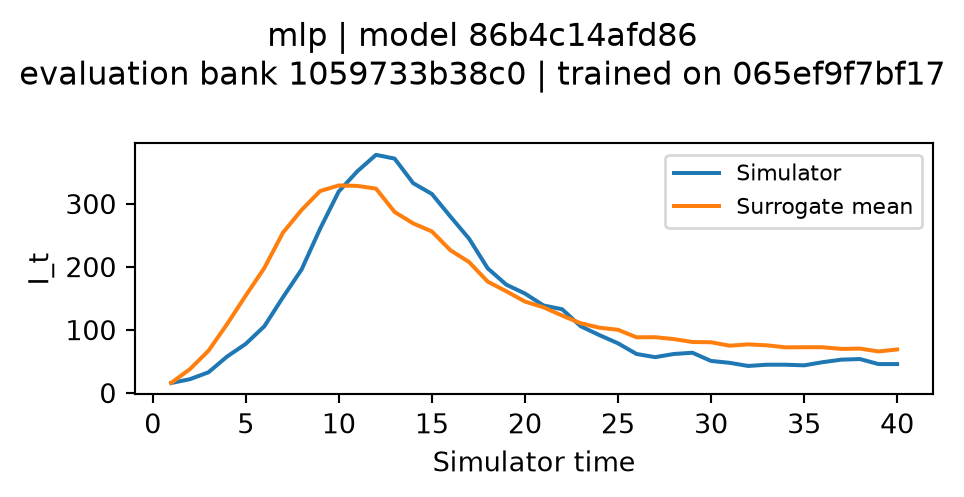

In [4]:
#| label: fig-selected-test
#| fig-cap: 'Validation-selected neural model fitted to the SIRDS training partition: infected-count prediction against a held-out test realization.'
fig = final_report.plot(output="I_t", max_runs=1)
plt.show()

*Validation-selected neural model fitted to the SIRDS training partition: infected-count prediction against a held-out test realization.*

Once test results influence your tuning, they no longer provide an independent
final assessment. Use a fresh test bank for the next claim.

## Diagnose a disappointing fit

| What you see | What to try |
|---|---|
| Training and validation losses both stay high | Check input/output pairing; fit a tiny subset; compare learning rates and longer training |
| Training improves but validation worsens | Try fewer parameters, early stopping with `TrainingConfig(patience=...)`, or more independent scenarios |
| Transformer loss is low but generated paths drift | Compare full predictions with an MLP; training uses observed history, deployment generates its own |
| Mean predictions look good but variability is wrong | Inspect [predictive intervals and CRPS](https://ojwatson.github.io/metis/package/evaluation.html), plus temporal and cross-output dependence |
| Errors cluster in particular parameter regions | Inspect those simulations and [coverage gaps](https://ojwatson.github.io/metis/package/evaluation.html#suggest-new-parameter-settings) |

Model families optimize different losses, so compare them using common
prediction metrics rather than raw training loss. Repeat seeds and splits when
you need to establish how stable a model choice is.